# 5-loyiha
Diabetes datasetida regressiya va Pipeline

Scikit-learn diabetes: haqiqiy ochiq dataset. Target bir yildan keyingi kasallik rivojining miqdoriy ko‘rsatkichi; diabet bor/yo‘q emas.


In [1]:
# Diabetes datasetida regressiya va Pipeline
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = (Path(__file__).resolve().parent
        if "__file__" in globals() else Path.cwd())
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 42

def save_json(name, value):
    text = json.dumps(value, indent=2, ensure_ascii=False,
                      allow_nan=False, default=str)
    (OUT / name).write_text(text, encoding="utf-8")

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140)
    plt.close()

import joblib
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (mean_absolute_error,
    root_mean_squared_error, r2_score)

def main():
    data = load_diabetes(as_frame=True)
    X, y = data.data, data.target
    X.assign(progression=y).to_csv(DATA / "diabetes.csv", index=False)
    train, test = train_test_split(np.arange(len(y)),
        test_size=0.2, random_state=SEED)
    model = GridSearchCV(make_pipeline(StandardScaler(), Ridge()),
        {"ridge__alpha": [0.1, 1, 10, 100]}, cv=5,
        scoring="neg_root_mean_squared_error")
    model.fit(X.iloc[train], y.iloc[train])
    baseline = DummyRegressor().fit(X.iloc[train], y.iloc[train])
    results = []
    for name, fitted in [("Ridge_CV", model), ("Dummy", baseline)]:
        pred = fitted.predict(X.iloc[test])
        results.append({"model": name,
            "mae": mean_absolute_error(y.iloc[test], pred),
            "rmse": root_mean_squared_error(y.iloc[test], pred),
            "r2": r2_score(y.iloc[test], pred)})
    pd.DataFrame(results).to_csv(OUT / "comparison.csv", index=False)
    pred = model.predict(X.iloc[test])
    pd.DataFrame({"row_id": test, "y_true": y.iloc[test],
        "prediction": pred}).to_csv(OUT / "predictions.csv", index=False)
    plt.scatter(y.iloc[test], pred, alpha=0.7)
    limits = [float(y.min()), float(y.max())]
    plt.plot(limits, limits, "k--")
    plt.xlabel("Haqiqiy progression")
    plt.ylabel("Bashorat")
    save_plot("predicted_vs_actual.png")
    joblib.dump(model.best_estimator_, OUT / "model.joblib")
    save_json("summary.json", {"n_train": len(train),
        "n_test": len(test), "best_params": model.best_params_,
        "task": "regression", "target": "one_year_progression"})
    save_json("split.json", {"train": train.tolist(),
                             "test": test.tolist()})
    print(pd.DataFrame(results).to_string(index=False))

if __name__ == "__main__":
    main()


   model       mae      rmse        r2
Ridge_CV 42.856825 53.626288  0.457211
   Dummy 64.006461 73.222493 -0.011963


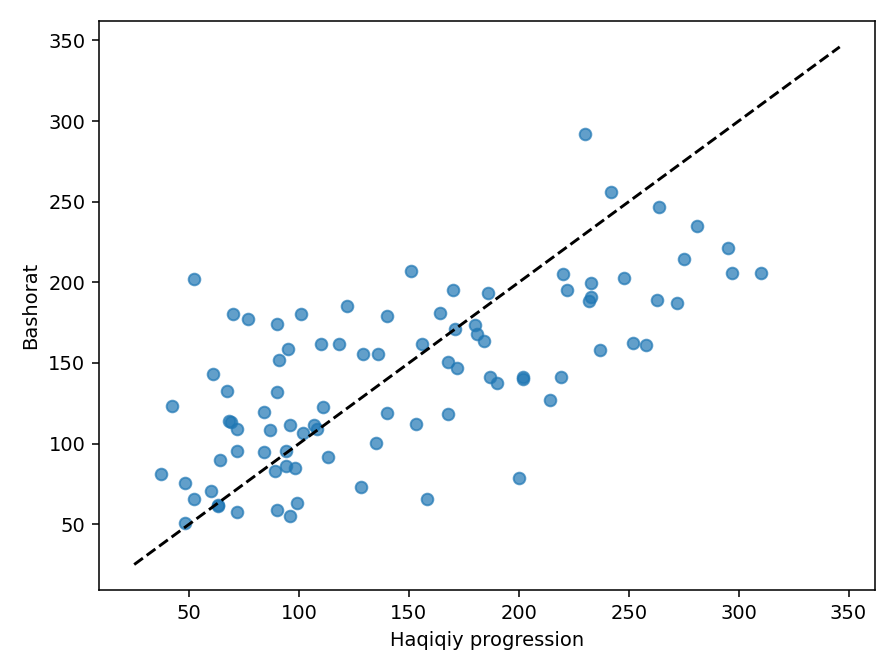

In [2]:
from IPython.display import display, Image
for path in sorted(OUT.glob("*.png")):
    display(Image(filename=str(path)))
